# Detection and segmentation with Faster R-CNN, Mask R-CNN, and DETR

This notebook introduces object detection and instance segmentation by moving from standard bounding-box detection to mask-based instance segmentation, and then contrasting both with a transformer-based detector.

Primary libraries:

- **TorchVision** for Faster R-CNN and Mask R-CNN internals.
- **Hugging Face Transformers** for the optional DETR demo.

Reference docs:

- TorchVision Faster R-CNN: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.fasterrcnn_resnet50_fpn_v2.html
- TorchVision Mask R-CNN: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn.html
- Hugging Face DETR: https://huggingface.co/docs/transformers/en/model_doc/detr


# Table of Contents

1. [Setup](#setup)
2. [Load an example image](#load-an-example-image)
3. [Object detection problem formulation](#1-object-detection-problem-formulation)
4. [Faster R-CNN: external behavior first](#2-faster-r-cnn)
5. [Backbone and feature maps](#3-backbone-and-feature-maps)
6. [Region Proposal Network](#4-region-proposal-network)
7. [RoI pooling / RoI feature extraction](#5-roi-pooling--roi-feature-extraction)
8. [Box head and box predictor](#6-box-head-and-box-predictor)
9. [Faster R-CNN loss calculation](#7-faster-r-cnn-loss-calculation)
10. [From detection to instance segmentation](#8-from-detection-to-instance-segmentation)
11. [Mask R-CNN overview](#9-mask-r-cnn-overview)
12. [RoI Align](#10-roi-align)
13. [Mask head](#11-mask-head)
14. [Mask R-CNN loss calculation](#12-mask-r-cnn-loss-calculation)
15. [DETR: a modern transformer-based contrast](#13-detr-a-modern-transformer-based-contrast)
16. [Evaluation metrics: IoU, AP, and mAP](#14-evaluation-metrics-iou-ap-and-map)
17. [Summary](#15-summary)
18. [Suggested classroom discussion questions](#suggested-classroom-discussion-questions)


## Learning objectives

By the end of this notebook, you should be able to explain:

- What bounding boxes, labels, confidence scores, and masks represent.
- How IoU and non-maximum suppression help clean up detection outputs.
- Why two-stage detectors first propose regions and then classify/refine them.
- What the Region Proposal Network does in Faster R-CNN.
- How anchors, objectness, and bounding-box regression fit together.
- Why RoI feature extraction is needed.
- What the box head predicts.
- What losses Faster R-CNN optimizes during training.
- The difference between semantic segmentation and instance segmentation.
- How Mask R-CNN extends Faster R-CNN with RoI Align and a mask head.
- How DETR differs from region-based detectors.


## Setup

First complete the [shared course setup](../../README.md#environment-setup), using the root [requirements.txt](../../requirements.txt). Run this notebook from its own directory so that `helper_functions.py` and `images/Oranges.png` can be found.

The following cells import the libraries and choose a compute device.


In [1]:
from __future__ import annotations

import inspect
import textwrap
from pathlib import Path
from typing import Dict, List, Mapping, Sequence

import torch
import torchvision
from torchvision.ops import box_iou, nms
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from torchvision.models.resnet import Bottleneck
from torchvision.models.detection.roi_heads import fastrcnn_loss

from helper_functions import show_image_tensor, pil_to_tensor_uint8, pil_to_tensor_float, show_source, category_name, visualize_detection_prediction, visualize_instance_segmentation_prediction  

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
device: cuda


## Load an example image

**Image provenance:** Generated with ChatGPT and provided by the course author. The bundled input is [Oranges.png](images/Oranges.png).

PIL size: (941, 1672)
Tensor shape: torch.Size([3, 1672, 941])


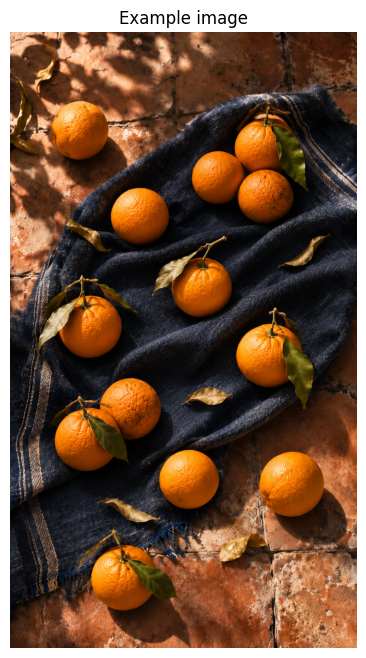

In [2]:
INPUT_IMAGE_PATH = Path("images/Oranges.png")

image = Image.open(INPUT_IMAGE_PATH).convert("RGB")
image_tensor_uint8 = pil_to_tensor_uint8(image)
image_tensor = pil_to_tensor_float(image)

print("PIL size:", image.size)  # (width, height)
print("Tensor shape:", image_tensor.shape)  # [C, H, W]
show_image_tensor(image_tensor, title="Example image")


The `uint8` tensor is useful for drawing boxes and masks because TorchVision visualization utilities expect pixel values from 0 to 255. The floating-point tensor is useful for neural-network input.


## 1. Object detection problem formulation

Image classification predicts one label for an image. Object detection predicts a **set of objects**, and each object prediction usually contains:

- a bounding box,
- a class label,
- a confidence score.

A useful framing is: classification answers *what is in the image?* Detection answers *what objects are present and where are they?*

Two concepts are especially important:

- **IoU**, or Intersection over Union, measures how much two boxes overlap.
- **NMS**, or non-maximum suppression, removes duplicate detections by keeping the highest-confidence box among heavily overlapping boxes.

For two boxes, IoU is:

```text
IoU = area of overlap / area of union
```


In [3]:
# Toy example: overlapping boxes around object candidates.
# These boxes are defined relative to the image size.

_, image_h, image_w = image_tensor_uint8.shape

toy_boxes = torch.tensor([
    [0.10 * image_w, 0.20 * image_h, 0.45 * image_w, 0.80 * image_h],  # high-confidence candidate
    [0.13 * image_w, 0.23 * image_h, 0.43 * image_w, 0.77 * image_h],  # overlapping duplicate
    [0.55 * image_w, 0.22 * image_h, 0.85 * image_w, 0.65 * image_h],  # separate candidate
], dtype=torch.float32)

toy_scores = torch.tensor([0.95, 0.80, 0.70])
toy_labels = ["candidate 0.95", "duplicate 0.80", "separate candidate 0.70"]

print("Toy boxes in (x1, y1, x2, y2) format:")
print(toy_boxes)

print("\nToy confidence scores:")
print(toy_scores)

print("\nPairwise IoU between toy boxes:")
print(box_iou(toy_boxes, toy_boxes))

keep = nms(toy_boxes, toy_scores, iou_threshold=0.5)
print("\nBoxes kept by NMS:", keep.tolist())
print("Labels kept by NMS:", [toy_labels[i] for i in keep.tolist()])


Toy boxes in (x1, y1, x2, y2) format:
tensor([[  94.1000,  334.4000,  423.4500, 1337.6000],
        [ 122.3300,  384.5600,  404.6300, 1287.4399],
        [ 517.5500,  367.8400,  799.8500, 1086.8000]])

Toy confidence scores:
tensor([0.9500, 0.8000, 0.7000])

Pairwise IoU between toy boxes:
tensor([[1.0000, 0.7714, 0.0000],
        [0.7714, 1.0000, 0.0000],
        [0.0000, 0.0000, 1.0000]])

Boxes kept by NMS: [0, 2]
Labels kept by NMS: ['candidate 0.95', 'separate candidate 0.70']


The two first boxes intentionally overlap heavily, so NMS keeps the stronger detection and removes the weaker duplicate. The third box is separate enough to survive.


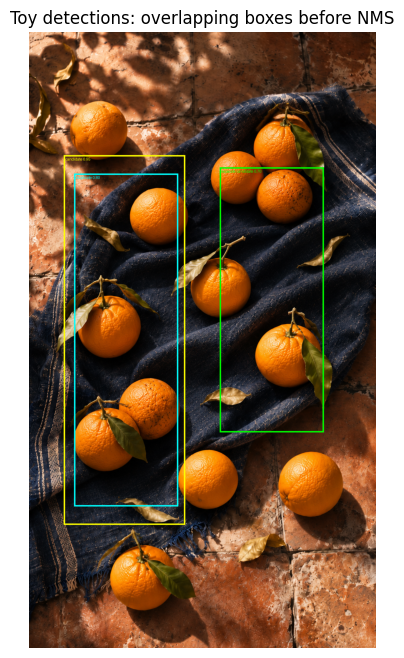

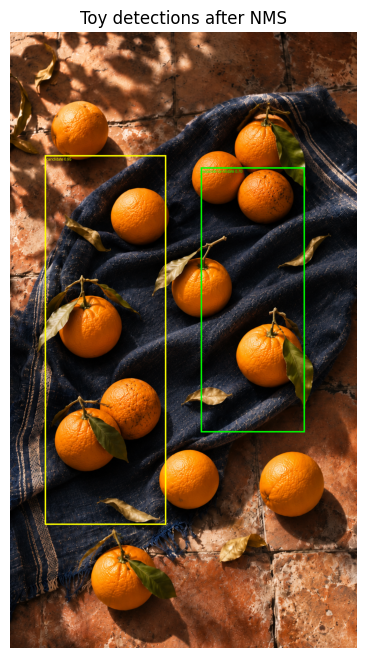

In [4]:
toy_box_colors = ["yellow", "cyan", "lime"]

drawn = draw_bounding_boxes(
    image_tensor_uint8,
    boxes=toy_boxes.to(torch.int64),
    labels=toy_labels,
    colors=toy_box_colors,
    width=4,
)
show_image_tensor(drawn, title="Toy detections: overlapping boxes before NMS")

kept_drawn = draw_bounding_boxes(
    image_tensor_uint8,
    boxes=toy_boxes[keep].to(torch.int64),
    labels=[toy_labels[i] for i in keep.tolist()],
    colors=[toy_box_colors[i] for i in keep.tolist()],
    width=4,
)
show_image_tensor(kept_drawn, title="Toy detections after NMS")


### 1.1 Key takeaways: detection outputs and NMS

- Detector outputs are usually boxes, labels, and confidence scores.
- IoU measures spatial overlap.
- NMS removes duplicate overlapping boxes by keeping the highest-confidence prediction.


## 2. Faster R-CNN

Faster R-CNN is a **two-stage object detector**:

1. **Stage 1:** propose possible object regions.
2. **Stage 2:** classify and refine those regions.

Before inspecting internals, first run the full pretrained model and look at its external prediction format.


In [5]:
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2

faster_weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
faster_categories = faster_weights.meta["categories"]
faster_transforms = faster_weights.transforms()

faster_model = fasterrcnn_resnet50_fpn_v2(weights=faster_weights).to(device)
faster_model.eval()

# TorchVision detection models expect a list of tensors, each [C, H, W].
# The weights transform prepares the image in the format expected by this model.
faster_input = faster_transforms(image).to(device)

with torch.no_grad():
    faster_prediction = faster_model([faster_input])[0]

print("Prediction keys:", faster_prediction.keys())
print("boxes:", tuple(faster_prediction["boxes"].shape))
print("labels:", tuple(faster_prediction["labels"].shape))
print("scores:", tuple(faster_prediction["scores"].shape))


Prediction keys: dict_keys(['boxes', 'labels', 'scores'])
boxes: (32, 4)
labels: (32,)
scores: (32,)


The model returns a dictionary with boxes, labels, and scores. Each row corresponds to one proposed object after the full detection pipeline and post-processing.


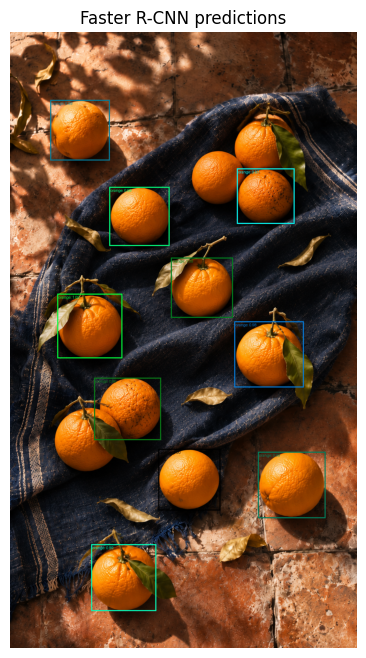

In [6]:
visualize_detection_prediction(
    image_tensor_uint8,
    faster_prediction,
    faster_categories,
    score_threshold=0.6,
    title="Faster R-CNN predictions",
)


The rest of the Faster R-CNN section unpacks how the model produced these predictions.

```text
Image
  ↓
Backbone CNN / FPN
  ↓
Feature maps
  ↓
Region Proposal Network (RPN)
  ↓
Candidate regions / proposals
  ↓
RoI feature extraction
  ↓
Box head
  ↓
Classes + refined boxes
```


## 3. Backbone and feature maps

The backbone converts the image into feature maps. Many modern detection models use a **Feature Pyramid Network (FPN)** so the detector can use multiple feature-map resolutions.

Why this matters:

- small objects need high-resolution features,
- large objects can use lower-resolution, more semantic features.


In [7]:
# The model has an internal transform step that batches, normalizes, and resizes images.
# We can call it directly to inspect intermediate shapes.

with torch.no_grad():
    images, _ = faster_model.transform([faster_input], None)
    features = faster_model.backbone(images.tensors)

print("Transformed image batch:", tuple(images.tensors.shape))
print("Feature container:", type(features))
for name, fmap in features.items():
    print(f"Feature map {name}: {tuple(fmap.shape)}")


Transformed image batch: (1, 3, 1344, 768)
Feature container: <class 'collections.OrderedDict'>
Feature map 0: (1, 256, 336, 192)
Feature map 1: (1, 256, 168, 96)
Feature map 2: (1, 256, 84, 48)
Feature map 3: (1, 256, 42, 24)
Feature map pool: (1, 256, 21, 12)


The backbone produces several feature maps at different resolutions. The RPN will use these features to propose candidate object regions.


### Source code of the Backbone

In [8]:
show_source(
    Bottleneck.forward,
    "ResNet Bottleneck.forward: convolutions create new feature maps",
    max_lines=80,
)

### ResNet Bottleneck.forward: convolutions create new feature maps

```python
def forward(self, x: Tensor) -> Tensor:
    identity = x

    out = self.conv1(x)
    out = self.bn1(out)
    out = self.relu(out)

    out = self.conv2(out)
    out = self.bn2(out)
    out = self.relu(out)

    out = self.conv3(out)
    out = self.bn3(out)

    if self.downsample is not None:
        identity = self.downsample(x)

    out += identity
    out = self.relu(out)

    return out

```

This ResNet bottleneck block creates a new feature map by applying three convolutions with normalization and ReLU activations. It then adds the original input back through a residual connection, so the block learns a refinement of the input rather than an entirely new representation from scratch. If the feature-map size or channel count changes, the downsample path adjusts the identity tensor before the addition.

In [9]:
show_source(
    type(faster_model.backbone.fpn).forward,
    "FeaturePyramidNetwork.forward: building multi-scale feature maps",
    max_lines=60,
)


### FeaturePyramidNetwork.forward: building multi-scale feature maps

```python
def forward(self, x: dict[str, Tensor]) -> dict[str, Tensor]:
    """
    Computes the FPN for a set of feature maps.

    Args:
        x (OrderedDict[Tensor]): feature maps for each feature level.

    Returns:
        results (OrderedDict[Tensor]): feature maps after FPN layers.
            They are ordered from the highest resolution first.
    """
    # unpack OrderedDict into two lists for easier handling
    names = list(x.keys())
    x = list(x.values())

    last_inner = self.get_result_from_inner_blocks(x[-1], -1)
    results = []
    results.append(self.get_result_from_layer_blocks(last_inner, -1))

    for idx in range(len(x) - 2, -1, -1):
        inner_lateral = self.get_result_from_inner_blocks(x[idx], idx)
        feat_shape = inner_lateral.shape[-2:]
        inner_top_down = F.interpolate(last_inner, size=feat_shape, mode="nearest")
        last_inner = inner_lateral + inner_top_down
        results.insert(0, self.get_result_from_layer_blocks(last_inner, idx))

    if self.extra_blocks is not None:
        results, names = self.extra_blocks(results, x, names)

    # make it back an OrderedDict
    out = OrderedDict([(k, v) for k, v in zip(names, results)])

    return out

```

This Feature Pyramid Network takes several backbone feature maps from different depths and turns them into a multi-scale feature pyramid. It starts from the deepest feature map, then repeatedly upsamples it and adds it to a lateral projection from the next shallower feature map. The result is an ordered set of feature maps that combine strong semantic information with higher-resolution spatial detail.

## 4. Region Proposal Network

The **Region Proposal Network (RPN)** is the first stage of Faster R-CNN.

Before the RPN makes predictions, many **anchor boxes** are placed across the feature maps. These anchors are predefined candidate boxes with different sizes and aspect ratios.

For each anchor, the RPN predicts:

1. **Objectness:** is this anchor likely to contain an object?
2. **Box-regression offsets:** how should the anchor move and resize to better fit the object?

The RPN then applies the predicted offsets to the anchors to create **region proposals**. These proposals are candidate object regions that are passed to the second stage of Faster R-CNN.

Important: the RPN is **class-agnostic**. It does not predict `dog` or `car`; it predicts whether a region looks like it contains **some object**.


In [10]:
print(faster_model.rpn)


RegionProposalNetwork(
  (anchor_generator): AnchorGenerator()
  (head): RPNHead(
    (conv): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
      (1): Conv2dNormActivation(
        (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
      )
    )
    (cls_logits): Conv2d(256, 3, kernel_size=(1, 1), stride=(1, 1))
    (bbox_pred): Conv2d(256, 12, kernel_size=(1, 1), stride=(1, 1))
  )
)


### 4.1 Anchors

Anchors are predefined boxes placed densely across the feature maps. At each feature-map location, the model considers anchors of different sizes and aspect ratios. The RPN then learns how to shift and resize these anchors.

The first source inspection shows how base anchor shapes are created. The second source inspection shows how those base anchors are tiled across the feature-map grid.


In [11]:
AnchorGeneratorClass = type(faster_model.rpn.anchor_generator)

show_source(
    AnchorGeneratorClass.generate_anchors,
    "AnchorGenerator.generate_anchors: base anchor shapes",
    max_lines=80,
)

if hasattr(AnchorGeneratorClass, "grid_anchors"):
    show_source(
        AnchorGeneratorClass.grid_anchors,
        "AnchorGenerator.grid_anchors: tile anchors over feature maps",
        max_lines=100,
    )


### AnchorGenerator.generate_anchors: base anchor shapes

```python
def generate_anchors(
    self,
    scales: list[int],
    aspect_ratios: list[float],
    dtype: torch.dtype = torch.float32,
    device: torch.device = torch.device("cpu"),
) -> Tensor:
    scales = torch.as_tensor(scales, dtype=dtype, device=device)
    aspect_ratios = torch.as_tensor(aspect_ratios, dtype=dtype, device=device)
    h_ratios = torch.sqrt(aspect_ratios)
    w_ratios = 1 / h_ratios

    ws = (w_ratios[:, None] * scales[None, :]).view(-1)
    hs = (h_ratios[:, None] * scales[None, :]).view(-1)

    base_anchors = torch.stack([-ws, -hs, ws, hs], dim=1) / 2
    return base_anchors.round()

```

### AnchorGenerator.grid_anchors: tile anchors over feature maps

```python
def grid_anchors(self, grid_sizes: list[list[int]], strides: list[list[Tensor]]) -> list[Tensor]:
    anchors = []
    cell_anchors = self.cell_anchors
    torch._assert(cell_anchors is not None, "cell_anchors should not be None")
    torch._assert(
        len(grid_sizes) == len(strides) == len(cell_anchors),
        "Anchors should be Tuple[Tuple[int]] because each feature "
        "map could potentially have different sizes and aspect ratios. "
        "There needs to be a match between the number of "
        "feature maps passed and the number of sizes / aspect ratios specified.",
    )

    for size, stride, base_anchors in zip(grid_sizes, strides, cell_anchors):
        grid_height, grid_width = size
        stride_height, stride_width = stride
        device = base_anchors.device

        # For output anchor, compute [x_center, y_center, x_center, y_center]
        shifts_x = torch.arange(0, grid_width, dtype=torch.int32, device=device) * stride_width
        shifts_y = torch.arange(0, grid_height, dtype=torch.int32, device=device) * stride_height
        shift_y, shift_x = torch.meshgrid(shifts_y, shifts_x, indexing="ij")
        shift_x = shift_x.reshape(-1)
        shift_y = shift_y.reshape(-1)
        shifts = torch.stack((shift_x, shift_y, shift_x, shift_y), dim=1)

        # For every (base anchor, output anchor) pair,
        # offset each zero-centered base anchor by the center of the output anchor.
        anchors.append((shifts.view(-1, 1, 4) + base_anchors.view(1, -1, 4)).reshape(-1, 4))

    return anchors

```

### Back to our example image

In [12]:
with torch.no_grad():
    feature_maps = list(features.values())
    anchors = faster_model.rpn.anchor_generator(images, feature_maps)

print("Number of images:", len(anchors))
print("Anchors for image 0:", anchors[0].shape)
print("First 5 anchors:")
print(anchors[0][:5])


Number of images: 1
Anchors for image 0: torch.Size([257796, 4])
First 5 anchors:
tensor([[-23., -11.,  23.,  11.],
        [-16., -16.,  16.,  16.],
        [-11., -23.,  11.,  23.],
        [-19., -11.,  27.,  11.],
        [-12., -16.,  20.,  16.]], device='cuda:0')


The output shape shows that a detector considers many candidate boxes before selecting a smaller number of proposals.


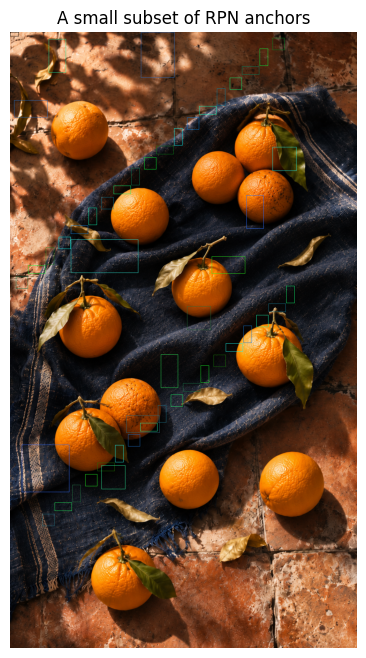

In [13]:
# Visualize a small subset of anchors.
# There are usually many thousands of anchors, so drawing all of them would be unreadable.

anchor_subset = anchors[0].detach().cpu()[::max(1, len(anchors[0]) // 50)][:50]
anchor_subset = anchor_subset.clamp(min=0)
anchor_subset[:, 0::2] = anchor_subset[:, 0::2].clamp(max=image.width)
anchor_subset[:, 1::2] = anchor_subset[:, 1::2].clamp(max=image.height)

drawn_anchors = draw_bounding_boxes(
    image_tensor_uint8,
    boxes=anchor_subset.to(torch.int64),
    labels=None,
    width=1,
)

show_image_tensor(drawn_anchors, title="A small subset of RPN anchors")


### 4.2 RPN proposals

The RPN turns dense anchors into a smaller list of candidate proposals.

During inference:

1. predict objectness scores and box offsets,
2. decode offsets into proposal boxes,
3. clip boxes to the image,
4. remove tiny boxes,
5. rank proposals,
6. apply NMS.

The source excerpt below is longer than the other source inspections because this method is central to Faster R-CNN.


In [14]:
show_source(
    type(faster_model.rpn).forward,
    "RegionProposalNetwork.forward: objectness, anchors, decoding, filtering, and losses",
    max_lines=38,
)


### RegionProposalNetwork.forward: objectness, anchors, decoding, filtering, and losses

```python
def forward(
    self,
    images: ImageList,
    features: dict[str, Tensor],
    targets: Optional[list[dict[str, Tensor]]] = None,
) -> tuple[list[Tensor], dict[str, Tensor]]:
    """
    Args:
        images (ImageList): images for which we want to compute the predictions
        features (Dict[str, Tensor]): features computed from the images that are
            used for computing the predictions. Each tensor in the list
            correspond to different feature levels
        targets (List[Dict[str, Tensor]]): ground-truth boxes present in the image (optional).
            If provided, each element in the dict should contain a field `boxes`,
            with the locations of the ground-truth boxes.

    Returns:
        boxes (List[Tensor]): the predicted boxes from the RPN, one Tensor per
            image.
        losses (Dict[str, Tensor]): the losses for the model during training. During
            testing, it is an empty dict.
    """
    # RPN uses all feature maps that are available
    features = list(features.values())
    objectness, pred_bbox_deltas = self.head(features)
    anchors = self.anchor_generator(images, features)

    num_images = len(anchors)
    num_anchors_per_level_shape_tensors = [o[0].shape for o in objectness]
    num_anchors_per_level = [s[0] * s[1] * s[2] for s in num_anchors_per_level_shape_tensors]
    objectness, pred_bbox_deltas = concat_box_prediction_layers(objectness, pred_bbox_deltas)
    # apply pred_bbox_deltas to anchors to obtain the decoded proposals
    # note that we detach the deltas because Faster R-CNN do not backprop through
    # the proposals
    proposals = self.box_coder.decode(pred_bbox_deltas.detach(), anchors)
    proposals = proposals.view(num_images, -1, 4)
    boxes, scores = self.filter_proposals(proposals, objectness, images.image_sizes, num_anchors_per_level)

# ... 14 more lines omitted to keep the notebook readable ...
```

### Back to our example image

In [15]:
with torch.no_grad():
    # targets=None means inference mode: return proposals instead of training losses.
    proposals, rpn_losses = faster_model.rpn(images, features, targets=None)

print("Number of images:", len(proposals))
print("Proposal tensor shape for image 0:", proposals[0].shape)
print("RPN losses in eval mode:", rpn_losses)
print("First 5 proposals:")
print(proposals[0][:5])


Number of images: 1
Proposal tensor shape for image 0: torch.Size([1000, 4])
RPN losses in eval mode: {}
First 5 proposals:
tensor([[ 535.9640,  908.8367,  681.6265, 1052.9750],
        [ 347.5372,  486.6704,  482.8018,  617.8934],
        [ 320.5988,  902.0198,  455.2895, 1035.0701],
        [ 214.5384,  334.8657,  344.5222,  461.7462],
        [ 102.0391,  565.2430,  242.5466,  705.4171]], device='cuda:0')


This manual call corresponds to the RPN stage of the full model. In evaluation mode, the RPN returns proposals and an empty loss dictionary because no ground-truth targets are provided. During training, it additionally matches anchors to targets and computes RPN classification and regression losses.


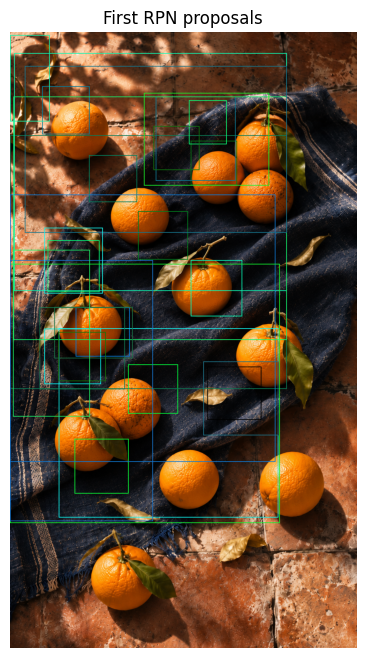

In [16]:
proposal_subset = proposals[0].detach().cpu()[:30]

drawn_proposals = draw_bounding_boxes(
    image_tensor_uint8,
    boxes=proposal_subset.to(torch.int64),
    labels=None,
    width=2,
)
show_image_tensor(drawn_proposals, title="First RPN proposals")


These proposals are no longer fixed anchors; they have been shifted and resized by the RPN. They are still class-agnostic candidate object regions.


## 5. RoI pooling / RoI feature extraction

The RPN proposals have different sizes. A neural-network head needs fixed-size inputs.

The original Faster R-CNN paper used **RoI Pooling**, which divides each proposal into bins and max-pools each bin. Modern TorchVision implementations use `MultiScaleRoIAlign` for FPN-based RoI feature extraction.

A useful simplification:

- **RoI Pooling:** fixed-size features, but involves coordinate quantization.
- **RoI Align:** fixed-size features without hard rounding, using bilinear interpolation.
- TorchVision's `box_roi_pool` turns variable-size proposals into fixed-size box features.


In [17]:
print(faster_model.roi_heads.box_roi_pool)


MultiScaleRoIAlign(featmap_names=['0', '1', '2', '3'], output_size=(7, 7), sampling_ratio=2)


The box RoI pool is a `MultiScaleRoIAlign` module. It selects appropriate FPN levels for proposals and converts variable-size regions into fixed-size feature tensors. The source inspection shows the Python-level control flow; the lower-level sampling operation is optimized internally.


In [18]:
show_source(
    type(faster_model.roi_heads.box_roi_pool).forward,
    "MultiScaleRoIAlign.forward: fixed-size RoI features",
    max_lines=100,
)


### MultiScaleRoIAlign.forward: fixed-size RoI features

```python
def forward(
    self,
    x: dict[str, Tensor],
    boxes: list[Tensor],
    image_shapes: list[tuple[int, int]],
) -> Tensor:
    """
    Args:
        x (OrderedDict[Tensor]): feature maps for each level. They are assumed to have
            all the same number of channels, but they can have different sizes.
        boxes (List[Tensor[N, 4]]): boxes to be used to perform the pooling operation, in
            (x1, y1, x2, y2) format and in the image reference size, not the feature map
            reference. The coordinate must satisfy ``0 <= x1 < x2`` and ``0 <= y1 < y2``.
        image_shapes (List[Tuple[height, width]]): the sizes of each image before they
            have been fed to a CNN to obtain feature maps. This allows us to infer the
            scale factor for each one of the levels to be pooled.
    Returns:
        result (Tensor)
    """
    x_filtered = _filter_input(x, self.featmap_names)
    if self.scales is None or self.map_levels is None:
        self.scales, self.map_levels = _setup_scales(
            x_filtered, image_shapes, self.canonical_scale, self.canonical_level
        )

    return _multiscale_roi_align(
        x_filtered,
        boxes,
        self.output_size,
        self.sampling_ratio,
        self.scales,
        self.map_levels,
    )

```

### Back to our example image

In [19]:
with torch.no_grad():
    box_roi_features = faster_model.roi_heads.box_roi_pool(
        features,
        proposals,
        images.image_sizes,
    )

print("Box RoI feature shape:", tuple(box_roi_features.shape))
print("Interpretation: [num_proposals, channels, pooled_height, pooled_width]")


Box RoI feature shape: (1000, 256, 7, 7)
Interpretation: [num_proposals, channels, pooled_height, pooled_width]


Each proposal may cover a different part of the image, but the output for each proposal has the same tensor shape. This fixed-size representation is what allows the next neural-network head to process all proposals uniformly.


## 6. Box head and box predictor

The box head is the second stage of Faster R-CNN. It receives fixed-size RoI features and predicts:

1. a class distribution for each proposal,
2. bounding-box refinements.

The box predictor usually returns:

- `class_logits`: one score vector per proposal,
- `box_regression`: coordinate refinements.


In [20]:
print("Box head:")
print(faster_model.roi_heads.box_head)

print("\nBox predictor:")
print(faster_model.roi_heads.box_predictor)


Box head:
FastRCNNConvFCHead(
  (0): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (1): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (2): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (3): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (4): Fla

The printed modules show the architecture. The source inspection below is targeted to the predictor's `forward` method, where the vector representation becomes class logits and box-regression values.


In [21]:
show_source(
    type(faster_model.roi_heads.box_predictor).forward,
    "FastRCNNPredictor.forward: classes and box deltas",
    max_lines=50,
)


### FastRCNNPredictor.forward: classes and box deltas

```python
def forward(self, x):
    if x.dim() == 4:
        torch._assert(
            list(x.shape[2:]) == [1, 1],
            f"x has the wrong shape, expecting the last two dimensions to be [1,1] instead of {list(x.shape[2:])}",
        )
    x = x.flatten(start_dim=1)
    scores = self.cls_score(x)
    bbox_deltas = self.bbox_pred(x)

    return scores, bbox_deltas

```

### Back to our example image

In [22]:
with torch.no_grad():
    # Convert pooled RoI features into vectors.
    box_head_features = faster_model.roi_heads.box_head(box_roi_features)

    # Second-stage classification and box-refinement predictions.
    class_logits, box_regression = faster_model.roi_heads.box_predictor(box_head_features)

print("Box-head feature shape:", tuple(box_head_features.shape))
print("Class logits shape:", tuple(class_logits.shape))
print("Box regression shape:", tuple(box_regression.shape))
print("Number of COCO categories including background:", len(faster_categories))


Box-head feature shape: (1000, 1024)
Class logits shape: (1000, 91)
Box regression shape: (1000, 364)
Number of COCO categories including background: 91


The manual calls above isolate the box branch. In the full model, these calls are orchestrated by `RoIHeads.forward`, which also handles proposal sampling, post-processing, and training losses.


## 7. Faster R-CNN loss calculation

During training, Faster R-CNN optimizes several losses at once.

Common loss terms:

- `loss_objectness`: RPN object/background classification.
- `loss_rpn_box_reg`: RPN anchor/proposal box regression.
- `loss_classifier`: final class prediction loss.
- `loss_box_reg`: final box refinement loss.

The total loss is usually the sum of these terms.

TorchVision makes this easy: in `train()` mode, the model returns a loss dictionary when targets are provided.

Targets must be a list of dictionaries, one per image:

```python
{
    "boxes": Tensor[N, 4],
    "labels": Tensor[N]
}
```

The following source inspection shows the second-stage Fast R-CNN classification and box-regression losses. The RPN losses are computed inside the RPN module shown earlier.


In [23]:
show_source(
    fastrcnn_loss,
    "fastrcnn_loss: classification and box-regression losses",
    max_lines=120,
)


### fastrcnn_loss: classification and box-regression losses

```python
def fastrcnn_loss(
    class_logits: torch.Tensor,
    box_regression: torch.Tensor,
    labels: list[torch.Tensor],
    regression_targets: list[torch.Tensor],
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Computes the loss for Faster R-CNN.

    Args:
        class_logits (Tensor)
        box_regression (Tensor)
        labels (list[BoxList])
        regression_targets (Tensor)

    Returns:
        classification_loss (Tensor)
        box_loss (Tensor)
    """

    labels = torch.cat(labels, dim=0)
    regression_targets = torch.cat(regression_targets, dim=0)

    classification_loss = F.cross_entropy(class_logits, labels)

    # get indices that correspond to the regression targets for
    # the corresponding ground truth labels, to be used with
    # advanced indexing
    sampled_pos_inds_subset = torch.where(labels > 0)[0]
    labels_pos = labels[sampled_pos_inds_subset]
    N, num_classes = class_logits.shape
    box_regression = box_regression.reshape(N, box_regression.size(-1) // 4, 4)

    box_loss = F.smooth_l1_loss(
        box_regression[sampled_pos_inds_subset, labels_pos],
        regression_targets[sampled_pos_inds_subset],
        beta=1 / 9,
        reduction="sum",
    )
    box_loss = box_loss / labels.numel()

    return classification_loss, box_loss

```

The next cell demonstrates the API shape rather than training a useful detector.

In [24]:
RUN_FASTER_LOSS_DEMO = True

if RUN_FASTER_LOSS_DEMO:
    faster_model.train()

    # Toy target only for API demonstration; this is not a real annotation.
    demo_label = faster_categories.index("orange") if "orange" in faster_categories else 1
    target = {
        "boxes": torch.tensor([[50.0, 30.0, 600.0, 700.0]], device=device),
        "labels": torch.tensor([demo_label], dtype=torch.int64, device=device),
    }

    loss_dict = faster_model([faster_input], [target])
    total_loss = sum(loss for loss in loss_dict.values())

    print(loss_dict)
    print("Total loss:", float(total_loss.detach().cpu()))

    faster_model.eval()
else:
    print("Set RUN_FASTER_LOSS_DEMO = True to run the Faster R-CNN training-loss example.")


{'loss_classifier': tensor(0.3280, device='cuda:0', grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.1537, device='cuda:0', grad_fn=<DivBackward0>), 'loss_objectness': tensor(0.0169, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.0184, device='cuda:0', grad_fn=<DivBackward0>)}
Total loss: 0.5170535445213318


### 7.1 Key takeaways: Faster R-CNN

- Faster R-CNN is a two-stage detector: proposal generation first, classification/refinement second.
- The RPN is class-agnostic; it asks whether a region likely contains any object.
- RoI feature extraction converts variable-size proposals into fixed-size tensors for the box head.
- During training, the model returns a dictionary of losses; during inference, it returns predictions.


## 8. From detection to instance segmentation

Before moving to Mask R-CNN, separate three related tasks:

- **Object detection:** predict a class label and bounding box for each object.
- **Semantic segmentation:** predict one class label for each pixel, without separating object instances.
- **Instance segmentation:** predict a separate mask for each object instance.

Mask R-CNN solves **instance segmentation**. It keeps the Faster R-CNN detection pipeline and adds a branch that predicts a foreground mask for each detected object.


## 9. Mask R-CNN overview

Mask R-CNN extends Faster R-CNN by adding an instance-segmentation branch. The model still detects objects with boxes, but also predicts a foreground mask inside each object region.

```text
Image
  ↓
Backbone / FPN
  ↓
RPN
  ↓
RoIs
  ↓
RoI Align
  ├─ Box head  → classes + boxes
  └─ Mask head → instance masks
```


In [25]:
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_Weights, maskrcnn_resnet50_fpn

mask_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mask_categories = mask_weights.meta["categories"]
mask_transforms = mask_weights.transforms()

mask_model = maskrcnn_resnet50_fpn(weights=mask_weights).to(device)
mask_model.eval()

mask_input = mask_transforms(image).to(device)

with torch.no_grad():
    mask_prediction = mask_model([mask_input])[0]

print("Prediction keys:", mask_prediction.keys())
print("boxes:", tuple(mask_prediction["boxes"].shape))
print("labels:", tuple(mask_prediction["labels"].shape))
print("scores:", tuple(mask_prediction["scores"].shape))
print("masks:", tuple(mask_prediction["masks"].shape))


Prediction keys: dict_keys(['boxes', 'labels', 'scores', 'masks'])
boxes: (21, 4)
labels: (21,)
scores: (21,)
masks: (21, 1, 1672, 941)


The boxes, labels, and scores are the usual detection outputs. The masks tensor adds one predicted mask per detected instance.


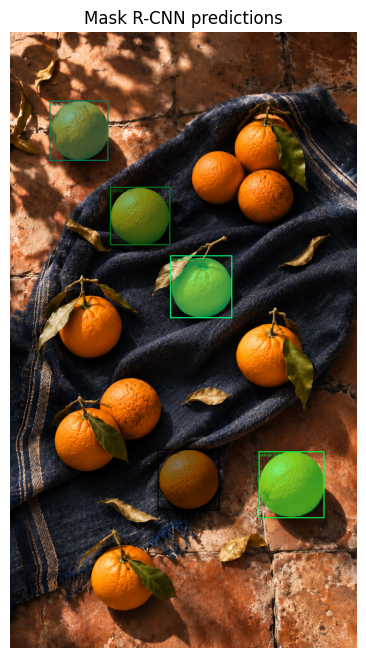

In [26]:
visualize_instance_segmentation_prediction(
    image_tensor_uint8,
    mask_prediction,
    mask_categories,
    score_threshold=0.7,
    title="Mask R-CNN predictions",
)


The architectural difference from Faster R-CNN lives inside `RoIHeads`: Mask R-CNN adds a mask-specific branch made of `mask_roi_pool`, `mask_head`, and `mask_predictor`.


In [27]:
print("Mask R-CNN RoI heads:")
print(mask_model.roi_heads)


Mask R-CNN RoI heads:
RoIHeads(
  (box_roi_pool): MultiScaleRoIAlign(featmap_names=['0', '1', '2', '3'], output_size=(7, 7), sampling_ratio=2)
  (box_head): TwoMLPHead(
    (fc6): Linear(in_features=12544, out_features=1024, bias=True)
    (fc7): Linear(in_features=1024, out_features=1024, bias=True)
  )
  (box_predictor): FastRCNNPredictor(
    (cls_score): Linear(in_features=1024, out_features=91, bias=True)
    (bbox_pred): Linear(in_features=1024, out_features=364, bias=True)
  )
  (mask_roi_pool): MultiScaleRoIAlign(featmap_names=['0', '1', '2', '3'], output_size=(14, 14), sampling_ratio=2)
  (mask_head): MaskRCNNHeads(
    (0): Conv2dNormActivation(
      (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
    )
    (2): Conv2dNormActivation(
      (0): Conv2d(256, 256, kernel_size=(3, 

## 10. RoI Align

Mask prediction is pixel-sensitive. Small spatial misalignments matter.

The original RoI Pooling operation used rounding/quantization to map continuous proposal coordinates onto feature-map bins. This can be acceptable for coarse bounding boxes, but it is harmful for masks.

**RoI Align** avoids that hard rounding:

- keeps floating-point coordinates,
- samples values at precise locations,
- uses bilinear interpolation.

This improves spatial alignment between the proposal, feature map, and final mask.


In [28]:
print("Box RoI pool:")
print(mask_model.roi_heads.box_roi_pool)

print("\nMask RoI pool:")
print(mask_model.roi_heads.mask_roi_pool)


Box RoI pool:
MultiScaleRoIAlign(featmap_names=['0', '1', '2', '3'], output_size=(7, 7), sampling_ratio=2)

Mask RoI pool:
MultiScaleRoIAlign(featmap_names=['0', '1', '2', '3'], output_size=(14, 14), sampling_ratio=2)


The box branch and mask branch both use RoI feature extraction, but they use different output sizes. The box branch usually uses compact `7 × 7` features; the mask branch preserves more spatial detail with `14 × 14` features before predicting `28 × 28` mask logits.


### 10.1 Toy RoI Align example

The real RoI Align operation is optimized and can call compiled kernels. For teaching, a tiny feature map is more helpful than digging into the low-level implementation. The example below asks RoI Align to extract a `2 × 2` feature map from fractional box coordinates.


In [29]:
from torchvision.ops import roi_align

# A single 5x5 feature map with values 0, 1, 2, ..., 24.
toy_feature_map = torch.arange(25, dtype=torch.float32).reshape(1, 1, 5, 5)

# RoI format: [batch_index, x1, y1, x2, y2].
# Fractional coordinates are intentional: RoI Align should avoid hard rounding.
toy_rois = torch.tensor([[0, 1.2, 1.2, 3.8, 3.8]], dtype=torch.float32)

toy_aligned = roi_align(
    toy_feature_map,
    toy_rois,
    output_size=(2, 2),
    spatial_scale=1.0,
    sampling_ratio=2,
    aligned=True,
)

print("Toy feature map:")
print(toy_feature_map[0, 0])
print("\nToy RoI:", toy_rois[0].tolist())
print("\nRoI Align output shape:", tuple(toy_aligned.shape))
print(toy_aligned[0, 0])


Toy feature map:
tensor([[ 0.,  1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.,  9.],
        [10., 11., 12., 13., 14.],
        [15., 16., 17., 18., 19.],
        [20., 21., 22., 23., 24.]])

Toy RoI: [0.0, 1.2000000476837158, 1.2000000476837158, 3.799999952316284, 3.799999952316284]

RoI Align output shape: (1, 1, 2, 2)
tensor([[ 8.1000,  9.4000],
        [14.6000, 15.9000]])


In [30]:
with torch.no_grad():
    mask_images, _ = mask_model.transform([mask_input], None)
    mask_features = mask_model.backbone(mask_images.tensors)
    mask_proposals, _ = mask_model.rpn(mask_images, mask_features, targets=None)

    mask_box_features = mask_model.roi_heads.box_roi_pool(
        mask_features,
        mask_proposals,
        mask_images.image_sizes,
    )

    print("Box RoI features:", tuple(mask_box_features.shape))
    print("Number of proposals for image 0:", mask_proposals[0].shape[0])


Box RoI features: (1000, 256, 7, 7)
Number of proposals for image 0: 1000


This cell runs the early part of Mask R-CNN manually: transform, backbone, RPN, and box RoI feature extraction. It mirrors the Faster R-CNN component inspection but uses the Mask R-CNN model.


## 11. Mask head

The mask head predicts a small segmentation mask for each RoI.

Unlike the box head, the mask head is convolutional because it must preserve spatial layout.

Typical Mask R-CNN output before resizing:

```text
[num_rois, num_classes, 28, 28]
```

For each positive RoI during training, the model uses the mask channel for the ground-truth class and applies a pixel-wise binary cross-entropy loss.


In [31]:
print("Mask head:")
print(mask_model.roi_heads.mask_head)

print("\nMask predictor:")
print(mask_model.roi_heads.mask_predictor)


Mask head:
MaskRCNNHeads(
  (0): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (1): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (2): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (3): Conv2dNormActivation(
    (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
)

Mask predictor:
MaskRCNNPredictor(
  (conv5_mask): ConvTranspose2d(256, 256, kernel_size=(2, 2), stride=(2, 2))
  (relu): ReLU(inplace=True)
  (mask_fcn_logits): Conv2d(256, 91, kernel_size=(1, 1), stride=(1, 1))
)


The next source inspection shows how the mask head is constructed as a stack of convolutional layers. Because the mask head subclasses `nn.Sequential`, its forward pass is the standard sequential application of those layers. The predictor source then shows how mask features become class-specific mask logits.


In [32]:
show_source(
    type(mask_model.roi_heads.mask_head),
    "MaskRCNNHeads: convolutional mask feature stack",
    max_lines=100,
)

### MaskRCNNHeads: convolutional mask feature stack

```python
class MaskRCNNHeads(nn.Sequential):
    _version = 2

    def __init__(self, in_channels, layers, dilation, norm_layer: Optional[Callable[..., nn.Module]] = None):
        """
        Args:
            in_channels (int): number of input channels
            layers (list): feature dimensions of each FCN layer
            dilation (int): dilation rate of kernel
            norm_layer (callable, optional): Module specifying the normalization layer to use. Default: None
        """
        blocks = []
        next_feature = in_channels
        for layer_features in layers:
            blocks.append(
                misc_nn_ops.Conv2dNormActivation(
                    next_feature,
                    layer_features,
                    kernel_size=3,
                    stride=1,
                    padding=dilation,
                    dilation=dilation,
                    norm_layer=norm_layer,
                )
            )
            next_feature = layer_features

        super().__init__(*blocks)
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

    def _load_from_state_dict(
        self,
        state_dict,
        prefix,
        local_metadata,
        strict,
        missing_keys,
        unexpected_keys,
        error_msgs,
    ):
        version = local_metadata.get("version", None)

        if version is None or version < 2:
            num_blocks = len(self)
            for i in range(num_blocks):
                for type in ["weight", "bias"]:
                    old_key = f"{prefix}mask_fcn{i+1}.{type}"
                    new_key = f"{prefix}{i}.0.{type}"
                    if old_key in state_dict:
                        state_dict[new_key] = state_dict.pop(old_key)

        super()._load_from_state_dict(
            state_dict,
            prefix,
            local_metadata,
            strict,
            missing_keys,
            unexpected_keys,
            error_msgs,
        )

```

### Back to our example image

In [33]:
# Branch-level demonstration: this shows the mask branch tensor shapes.
# It is not the exact final inference sequence. In full inference, the box branch
# first produces final detections; the mask branch then predicts masks for selected detections.

with torch.no_grad():
    raw_mask_features = mask_model.roi_heads.mask_roi_pool(
        mask_features,
        mask_proposals,
        mask_images.image_sizes,
    )
    raw_mask_features = mask_model.roi_heads.mask_head(raw_mask_features)
    raw_mask_logits = mask_model.roi_heads.mask_predictor(raw_mask_features)

print("Raw mask logits shape:", tuple(raw_mask_logits.shape))
print("Interpretation: [num_proposals, num_classes, mask_height, mask_width]")


Raw mask logits shape: (1000, 91, 28, 28)
Interpretation: [num_proposals, num_classes, mask_height, mask_width]


This branch-level demonstration is useful for understanding tensor shapes, but it is not the final inference path. In full Mask R-CNN inference, the box branch first classifies, refines, filters, and scores detections. The mask branch is then used to produce masks for selected detected instances.


## 12. Mask R-CNN loss calculation

Mask R-CNN adds a mask loss to the Faster R-CNN losses.

Common loss terms:

- `loss_objectness`
- `loss_rpn_box_reg`
- `loss_classifier`
- `loss_box_reg`
- `loss_mask`

Targets must include masks:

```python
{
    "boxes": Tensor[N, 4],
    "labels": Tensor[N],
    "masks": Tensor[N, H, W]
}
```

The additional `loss_mask` term is computed by a Mask R-CNN-specific helper. Inspecting this helper makes the difference from Faster R-CNN concrete: masks are selected for the matched class and trained with a per-pixel binary cross-entropy objective.


In [34]:
from torchvision.models.detection.roi_heads import maskrcnn_loss

show_source(
    maskrcnn_loss,
    "maskrcnn_loss: class-specific per-pixel mask loss",
    max_lines=120,
)


### maskrcnn_loss: class-specific per-pixel mask loss

```python
def maskrcnn_loss(mask_logits, proposals, gt_masks, gt_labels, mask_matched_idxs):
    # type: (Tensor, list[Tensor], list[Tensor], list[Tensor], list[Tensor]) -> Tensor
    """
    Args:
        proposals (list[BoxList])
        mask_logits (Tensor)
        targets (list[BoxList])

    Return:
        mask_loss (Tensor): scalar tensor containing the loss
    """

    discretization_size = mask_logits.shape[-1]
    labels = [gt_label[idxs] for gt_label, idxs in zip(gt_labels, mask_matched_idxs)]
    mask_targets = [
        project_masks_on_boxes(m, p, i, discretization_size) for m, p, i in zip(gt_masks, proposals, mask_matched_idxs)
    ]

    labels = torch.cat(labels, dim=0)
    mask_targets = torch.cat(mask_targets, dim=0)

    # torch.mean (in binary_cross_entropy_with_logits) doesn't
    # accept empty tensors, so handle it separately
    if mask_targets.numel() == 0:
        return mask_logits.sum() * 0

    mask_loss = F.binary_cross_entropy_with_logits(
        mask_logits[torch.arange(labels.shape[0], device=labels.device), labels], mask_targets
    )
    return mask_loss

```

The next cell is for illustrating the training API. 

In [35]:
RUN_MASK_LOSS_DEMO = True

if RUN_MASK_LOSS_DEMO:
    mask_model.train()

    H, W = image.height, image.width

    # Toy binary mask only for API demonstration; this is not a real annotation.
    toy_mask = torch.zeros((H, W), dtype=torch.uint8)
    toy_mask[30:min(700, H), 50:min(600, W)] = 1

    demo_label = mask_categories.index("orange") if "orange" in mask_categories else 1
    target = {
        "boxes": torch.tensor([[50.0, 30.0, min(600.0, float(W)), min(700.0, float(H))]], device=device),
        "labels": torch.tensor([demo_label], dtype=torch.int64, device=device),
        "masks": toy_mask.unsqueeze(0).to(device),
    }

    loss_dict = mask_model([mask_input], [target])
    total_loss = sum(loss for loss in loss_dict.values())

    print(loss_dict)
    print("Total loss:", float(total_loss.detach().cpu()))

    mask_model.eval()
else:
    print("Set RUN_MASK_LOSS_DEMO = True to run the Mask R-CNN training-loss example.")


{'loss_classifier': tensor(0.6555, device='cuda:0', grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.1370, device='cuda:0', grad_fn=<DivBackward0>), 'loss_mask': tensor(2.5886, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_objectness': tensor(0.0169, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.0143, device='cuda:0', grad_fn=<DivBackward0>)}
Total loss: 3.412260055541992


### 12.1 Key takeaways: Mask R-CNN

- Mask R-CNN adds a mask branch to Faster R-CNN.
- Bounding boxes localize objects coarsely; masks localize object pixels.
- RoI Align is important because mask prediction is sensitive to spatial alignment.
- Training targets must include instance masks in addition to boxes and labels.


## 13. DETR: a modern transformer-based contrast

DETR stands for **DEtection TRansformer**.

This section is a conceptual contrast with the region-proposal pipeline. Faster R-CNN and Mask R-CNN use anchors, proposals, RoI features, and NMS. DETR instead treats detection as **set prediction**: it directly predicts a fixed-size set of objects and learns a matching between predictions and ground truth.

Main ideas:

- A CNN backbone extracts image features.
- A transformer encoder-decoder reasons globally over the image.
- Learned object queries ask, in effect, “is there an object here?”
- A matching loss assigns predictions to ground-truth objects during training.
- Because predictions are trained as a set, DETR does not need hand-designed anchors or NMS in the same way.


The DETR demo is disabled by default because it downloads a Hugging Face model the first time it is run. Enable it when internet access and time are available.


In [36]:
RUN_DETR_DEMO = False

if RUN_DETR_DEMO:
    from transformers import AutoImageProcessor, AutoModelForObjectDetection

    detr_processor = AutoImageProcessor.from_pretrained("facebook/detr-resnet-50")
    detr_model = AutoModelForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device)
    detr_model.eval()

    inputs = detr_processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        detr_outputs = detr_model(**inputs)

    target_sizes = torch.tensor([image.size[::-1]], device=device)  # [height, width]
    detr_results = detr_processor.post_process_object_detection(
        detr_outputs,
        threshold=0.7,
        target_sizes=target_sizes,
    )[0]

    print(detr_results.keys())
    print("boxes:", detr_results["boxes"].shape)
    print("labels:", detr_results["labels"].shape)
    print("scores:", detr_results["scores"].shape)
else:
    print("Set RUN_DETR_DEMO = True to run DETR inference.")


Set RUN_DETR_DEMO = True to run DETR inference.


In [37]:
if "detr_results" in globals():
    detr_categories = detr_model.config.id2label

    detr_prediction = {
        "boxes": detr_results["boxes"],
        "labels": detr_results["labels"],
        "scores": detr_results["scores"],
    }

    visualize_detection_prediction(
        image_tensor_uint8,
        detr_prediction,
        detr_categories,
        score_threshold=0.7,
        title="DETR predictions",
    )
else:
    print("Run the DETR demo cell first.")


Run the DETR demo cell first.


### 13.1 Key takeaways: DETR

- DETR replaces proposal-based detection components with transformer-based set prediction.
- It avoids hand-designed anchors and the usual NMS-style duplicate-removal step.
- The trade-off is that DETR-style models often require careful training and enough data to learn the matching behavior well.


## 14. Evaluation metrics: IoU, AP, and mAP

For lecture use, it helps to separate **localization quality** from **dataset-level detection quality**.

- **IoU (Intersection over Union)** compares one predicted box or mask with one ground-truth box or mask. Higher IoU means better overlap.
- **Average Precision (AP)** summarizes the precision-recall curve for one class at one or more IoU thresholds.
- **mean Average Precision (mAP)** averages AP across classes, and sometimes across several IoU thresholds.

For COCO-style evaluation, people often report multiple metrics, such as box AP and mask AP, because detection and segmentation quality are related but not identical.

### 14.1 Key takeaways: evaluation

- A high confidence score does not guarantee accurate localization.
- IoU checks spatial overlap; AP/mAP checks detection quality across confidence thresholds.
- Detection and segmentation evaluations are stricter than classification accuracy because both class and location must be correct.


## 15. Summary

### 15.1 Faster R-CNN

- Two-stage detector.
- Stage 1: RPN proposes class-agnostic object regions.
- Stage 2: box head classifies and refines proposed regions.
- RoI feature extraction converts variable-size proposals into fixed-size tensors.
- Training combines RPN losses and box-head losses.

### 15.2 Mask R-CNN

- Adds instance segmentation to Faster R-CNN.
- Uses RoI Align to avoid spatial misalignment.
- Adds `mask_roi_pool`, a convolutional `mask_head`, and a `mask_predictor`.
- Adds a class-specific per-pixel `maskrcnn_loss`.

### 15.3 DETR

- Replaces much of the region-based pipeline with transformer set prediction.
- Uses object queries rather than anchors/proposals.
- Uses Hungarian matching during training.
- Provides a clean conceptual bridge from CNN feature extraction to transformer-based detection.

### 15.4 Inspecting internals responsibly

- `print(module)` shows the architecture and nested submodules.
- `show_source(type(module).forward)` shows selected Python-level code that is executed during a forward pass.
- Source inspection is most useful when it supports the concept currently being taught.
- For low-level operations such as NMS and RoI Align, small toy examples are often more useful than full library internals.


## Suggested classroom discussion questions

1. Why is object detection harder than image classification?
2. Why does Faster R-CNN use proposals instead of classifying every possible box?
3. What problem do anchors solve? What problems do they introduce?
4. Why does RoI feature extraction need fixed-size outputs?
5. Why is RoI Align especially important for masks?
6. Why is the mask head convolutional rather than fully connected?
7. What is the difference between semantic segmentation and instance segmentation?
8. What does DETR remove from the Faster R-CNN / Mask R-CNN pipeline?
9. What does DETR add conceptually?
10. When might a two-stage region-based detector still be useful?
11. When might a transformer-based detector be attractive?
